<a href="https://colab.research.google.com/github/KeshavFTW099/ArtificalAdvanced_NeuralNetworks/blob/main/Labinternal2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1924s 11us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.6589 - loss: 0.9844 - val_accuracy: 0.7670 - val_loss: 0.6715
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 53ms/step - accuracy: 0.7146 - loss: 0.8158 - val_accuracy: 0.7888 - val_loss: 0.6066
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 54ms/step - accuracy: 0.7282 - loss: 0.7763 - val_accuracy: 0.7975 - val_loss: 0.5874
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.7364 - loss: 0.7468 - val_accuracy: 0.7944 - val_loss: 0.5945
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.7441 - loss: 0.7234 - val_accuracy: 0.7992 - val_loss: 0.5715
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.7525 - loss: 0.7069 - val_accuracy: 0.7970 - val_loss: 0.5906
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 44s 56ms/step - accuracy: 0.7548 - loss: 0.6980 - val_accuracy: 0.8007 -

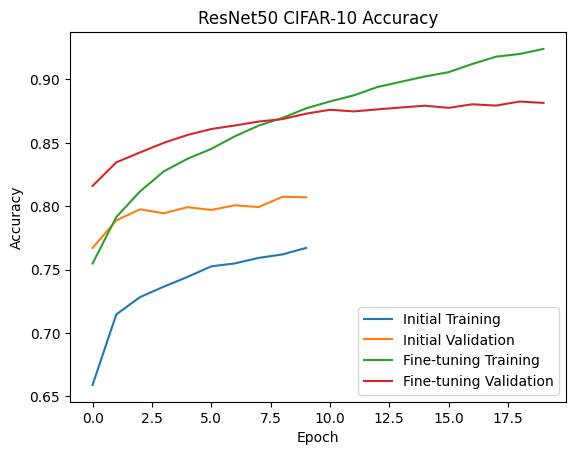

In [1]:
import tensorflow as tf
import time
import matplotlib.pyplot as plt

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, GlobalAveragePooling2D,
    Dropout, RandomFlip, RandomRotation,
    RandomZoom, Resizing
)
from tensorflow.keras.optimizers import Adam

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

#
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

#ResNet50 model
def build_resnet50():

    inputs = Input(shape=(32, 32, 3))


    x = Resizing(75, 75)(inputs)


    x = data_augmentation(x)

    x = preprocess_input(x)

    #ResNet50
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(75, 75, 3),
        pooling="avg"
    )

    # Freeze
    base.trainable = False

    x = base(x, training=False)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.3)(x)
    outputs = Dense(10, activation="softmax")(x)
    model = Model(inputs, outputs)

    return model, base

model, base = build_resnet50()

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()

history = model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=10,
    validation_data=(x_test, y_test)
)

base.trainable = True

for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


history_fine = model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=20,
    validation_data=(x_test, y_test)
)
end_time = time.time()

print("Training time:", end_time - start_time)

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy*100)
